In [28]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import datetime
import glob
import joblib
import shutil
import umap

sys.path.insert(0, "cellular_cycle") # add path to the model

from cell_cycle_death_model import model
from model_fxns import minmax_scale, stack_sliding_window

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
SAVEDIR = Path(Path.home(),'ECM_mod_output')
SAVE_DIR.mkdir(exist_ok=True)

OVERWRITE = True # Overwrite existing simulation files
SET_JPARAM = False # Set the parameter values for the simulation using PSO-optimized values

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

ORIG_SIM_DIR = Path(SAVE_DIR,'orig_sims')
USE_ORIGINAL = True # set to true to automatically download the original data from Dropbox
GENERATE_UMAP = True # Generate UMAP plots for the simulation output

output_from = 1 # 1: original 3: 03_ECM_model_output.ipynb 4: 04_Stoch_sims_for_UMAP.ipynb

sys_type = sys.platform

In [29]:
if USE_ORIGINAL and not ORIG_SIM_DIR.exists():
    print('Downloading original stochastic simulation data')
    if sys_type == 'win32':
        new_url = 'https://www.dropbox.com/scl/fi/j4c3d2ypdws50lks45lag/orig_sims.zip?rlkey=evill8yurm6dzq7dnf03036vf&dl=1'
        !curl -L -o orig_stoch_sims.zip $new_url
        !unzip orig_stoch_sims.zip
        !mv orig_sims $ORIG_SIM_DIR
        os.remove('orig_stoch_sims.zip')
        os.remove('_MACOSX', recursive=True)
    else:
        !wget 'https://www.dropbox.com/scl/fi/dn1mja4obyp7bw0ac8xna/stochastic_simulations.zip?rlkey=vx67yyrgtttzytq26yb26z7uw&dl=1' -O orig_stoch_sims.zip
        !unzip orig_stoch_sims.zip
        !mv stochastic_simulations $ORIG_SIM_DIR
        os.remove('orig_stoch_sims.zip')

In [30]:
exp_stiff_vals = ['000','049','099']

In [32]:
if SET_JPARAM:
    stoch_filenames_03 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_psoparam_cycdi_0_0' in f]
    stoch_filenames_03.sort()
    stoch_filenames_04 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_stiff_' in f]
    stoch_filenames_04.sort()
else:
    stoch_filenames_03 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_param_cycdi_0_0' in f]
    stoch_filenames_03.sort()
    stoch_filenames_04 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_stiff_' in f and 'orig' in f]
    stoch_filenames_04.sort()

if USE_ORIGINAL:
    stoch_filenames = [str(Path(ORIG_SIM_DIR, f)) for f in os.listdir(ORIG_SIM_DIR) if '.csv' in f and 'stoch_sim' in f]
else:
    stoch_filenames = globals()[f'stoch_filenames_0{output_from}']

stoch_filenames.sort()
stoch_filenames

['C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_029_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_074_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_029_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_074_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_099_orig.csv']

In [33]:
stoch_filenames_umap = [f for f in stoch_filenames if any([x in str(f) for x in exp_stiff_vals])]
stoch_filenames_umap

['C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_099_orig.csv']

In [34]:
ode_filenames = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames]
ode_filenames

[WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_099_orig.csv')]

In [35]:
ode_filenames_umap = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames_umap]
ode_filenames_umap

[WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_099_orig.csv')]

In [36]:
ODE_SAVE_DIR = Path(Path.home(),'ECM_mod_output/UMAP/ODE_embeddings')
ODE_SAVE_DIR.mkdir(parents=True, exist_ok=True)

OVERWRITE = True

sys_type = sys.platform

In [37]:
FILE_LOC = Path(Path.home(),'ECM_mod_output/ODE_output')
if SET_JPARAM:
    filenames = [Path(FILE_LOC,f) for f in os.listdir(FILE_LOC) if  'psoparam' in f]
else:
    filenames = [Path(FILE_LOC,f) for f in os.listdir(FILE_LOC) if  'range' in f]    
    
all_odes = sorted(filenames)

In [38]:
all_odes[1000]

WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_output/ERL_range_000.csv')

In [39]:
filenames_odes_dmso_100 = [str(all_odes[0])] + [str(x) for x in all_odes[9:1000:10]]
filenames_odes_erl_100 = [str(all_odes[1000])] + [str(x) for x in all_odes[1009:2000:10]]

In [40]:
filenames_odes_erl_100

['C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_000.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_009.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_019.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_029.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_039.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_049.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_059.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_069.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_079.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_089.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_099.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_109.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_119.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_129.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\

In [41]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 5

In [42]:
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240502'
    r_dbpath = 'https://www.dropbox.com/scl/fi/ovk8v5fc9rvsbm43zww8h/reducer_20240502_0.1_0.1_4_0.5.sav?rlkey=jb9om518rtjth0q9bs6mdjj79&dl=1'
if sys_type == 'win32': 
    sys_name = 'win'
    r_path_date = '03_20'
    r_dbpath = 'https://www.dropbox.com/scl/fi/jlfya4m3bhp9akr3hzco2/reducer_03_20_0.1_0.1_4_0.5.sav?rlkey=3z8ozy95khsjdqplkg8ce11md&dl=1'
if sys_type == 'linux': 
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

#reducer save name
if SET_JPARAM:
    r_name = f'reducer_psoparams_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'
else:
    r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [43]:
if not GENERATE_UMAP:
    r_path = Path(SAVE_DIR,'UMAP',r_name.replace(f'{sys_name}',r_path_date))
else:
    r_path = Path(SAVE_DIR,'UMAP',r_name)

%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=C:\Users\olesk\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/scl/fi/jlfya4m3bhp9akr3hzco2/reducer_03_20_0.1_0.1_4_0.5.sav?rlkey=3z8ozy95khsjdqplkg8ce11md&dl=1


In [16]:
def load_sim_output(filenames: list) -> pd.DataFrame:
    sim_data = pd.DataFrame()
    for i, f in enumerate(filenames):
        tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        tmp = tmp.drop(columns=['cdh1_inact'])
        if i == 0:
            sim_data = tmp
        else:
            sim_data = pd.concat([sim_data,tmp], ignore_index=True)
    return sim_data

def calc_minmax(filenames):
    dat = load_sim_output(filenames)
    min_prots = dat.min(axis=0).to_list()
    max_prots = dat.max(axis=0).tolist()
    return max_prots, min_prots

In [17]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames, filenames_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames, filenames_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [18]:
# max_prots, min_prots = calc_minmax(stoch_filenames, ode_filenames)
max_prots, min_prots = calc_minmax(stoch_filenames_umap + ode_filenames_umap)

In [21]:
trk_len = 2000

In [22]:
def get_traj(embed_dat, pos, trk_len=trk_len):
    if pos > len(embed_dat)/trk_len:
        print('Position out of range')
        return np.nan   
    embed_ode = embed_dat[pos*trk_len:(pos+1)*trk_len]
    return embed_ode

In [23]:
def plot_traj(embed_dat, pos, trk_len=trk_len, ax=None, color='gray', title=None):
    if title is None:
        title = f'{conds[pos]}'
    if ax is None:
        fig, ax = plt.subplots(figsize=(5,5))
    
    params = {'axes.titley': 1,
            'axes.titlepad': 5,
            'axes.labelsize': 16,
            'axes.edgecolor': "black",
            'axes.titlesize': 18,
            'xtick.labelsize': 14,
            'ytick.labelsize': 14}
    plt.rcParams.update(params)

    embed_ode = get_traj(embed_dat, pos, trk_len)
    ax.set_title(title)
    ax.plot(embed_ode[:,0], embed_ode[:,1], color=color, lw=0.1)
    return ax


In [24]:
 def calc_emb(f):
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
    
    ##### REMOVE after fixing ODE runs
    prot_tmp = prot_tmp.iloc[::10]
    ################################
    
    range_ind = np.arange(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt))
    #prot_tmp = prot_tmp/200
    for ii in range(18):
        prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
        #tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        #tmp_at = time_tmp2['time'].iloc[n]

        prot_re_tmp[ii,:] = np.array([tmp])
        #time_re_tmp[ii,:] = np.array([tmp_t])
        #time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1

    embedding_tmp = reducer.transform(prot_re_tmp)
    return embedding_tmp

In [25]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [26]:
windows = [2, 3, 4]
neighbors = [25, 50, 75]

Window 2 completed
Reducer 25 completed
Reducer 50 completed
Reducer 75 completed
Window 3 completed
Reducer 25 completed
Reducer 50 completed
Reducer 75 completed
Window 4 completed
Reducer 25 completed
Reducer 50 completed
Reducer 75 completed


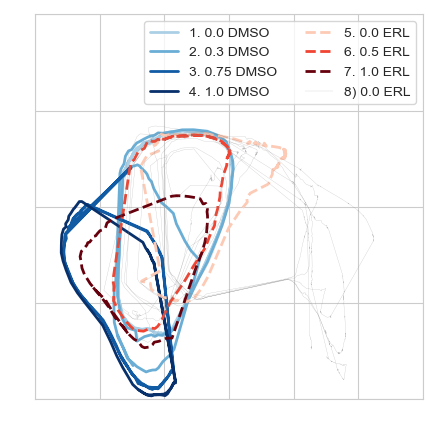

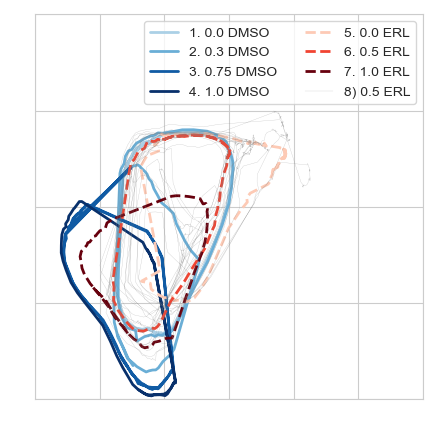

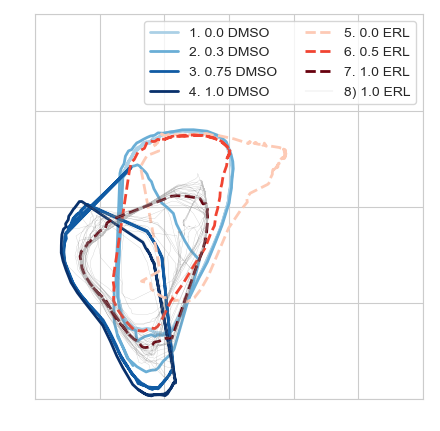

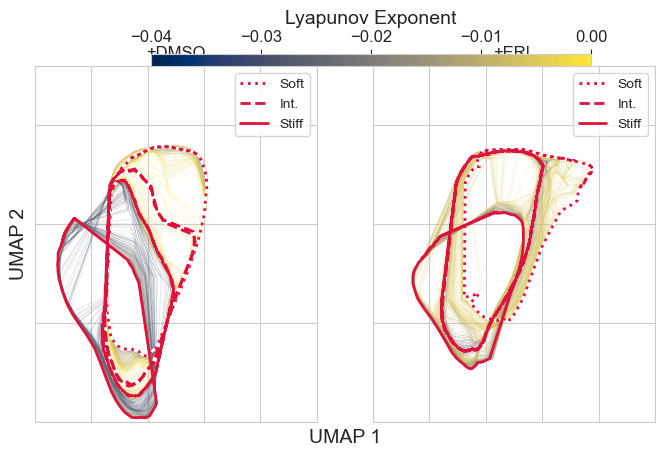

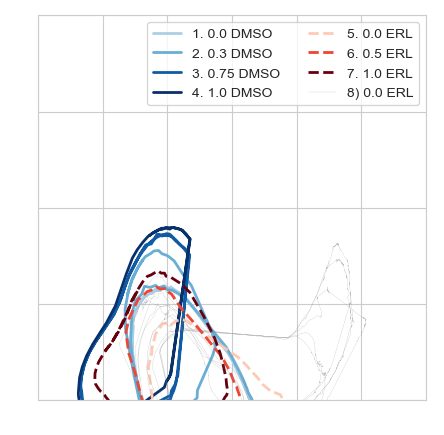

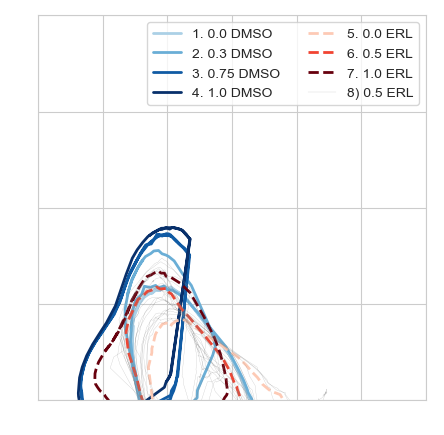

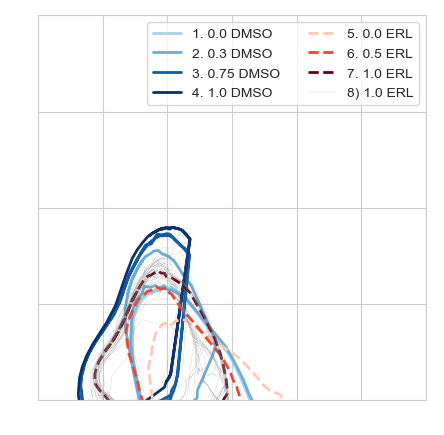

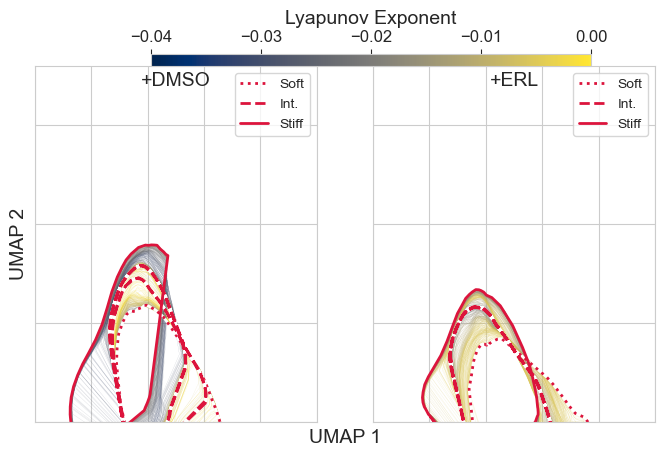

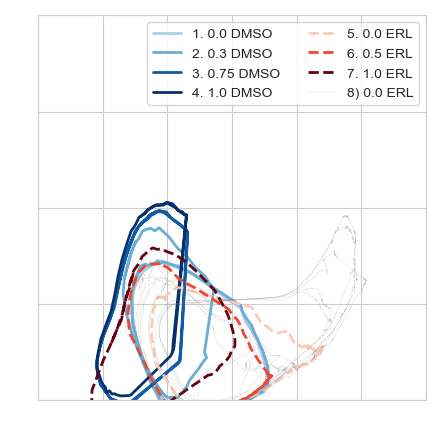

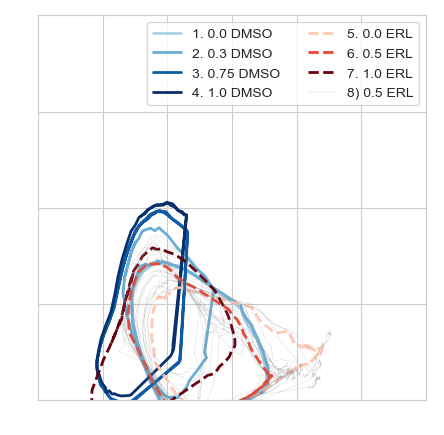

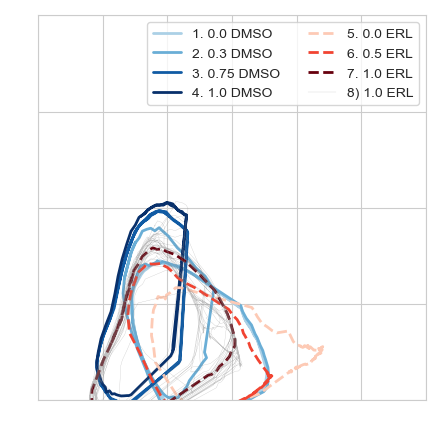

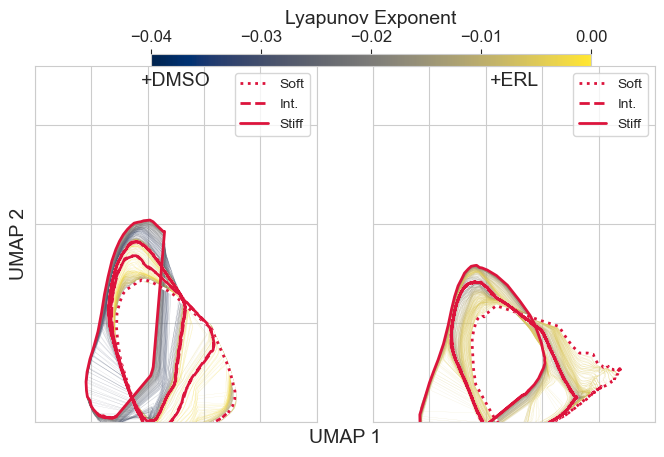

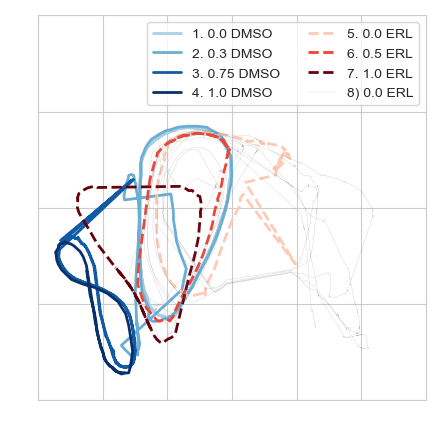

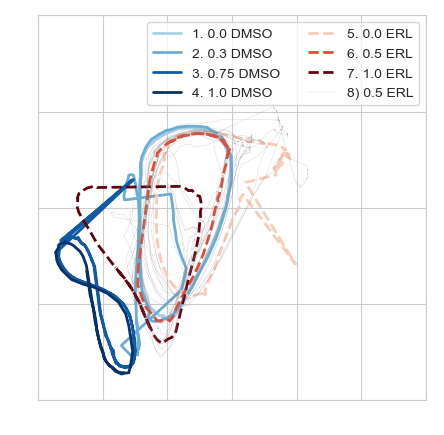

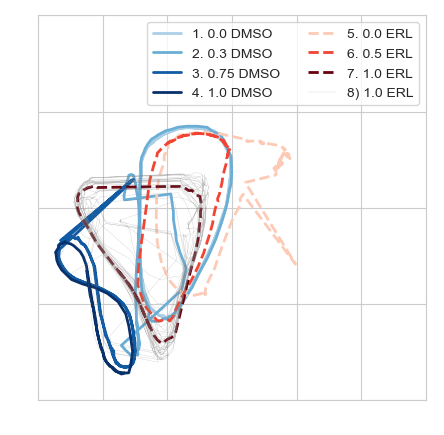

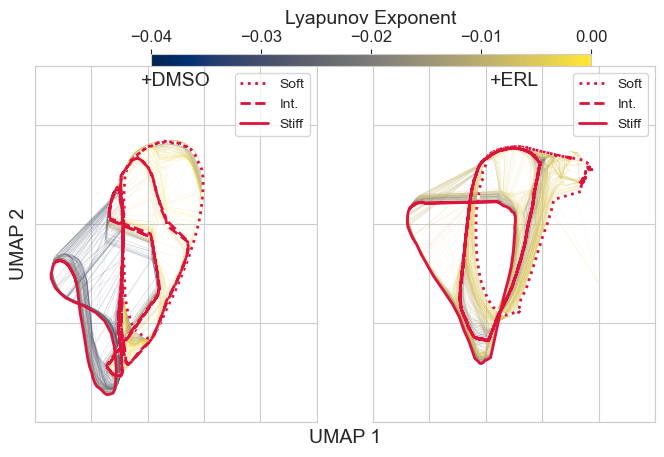

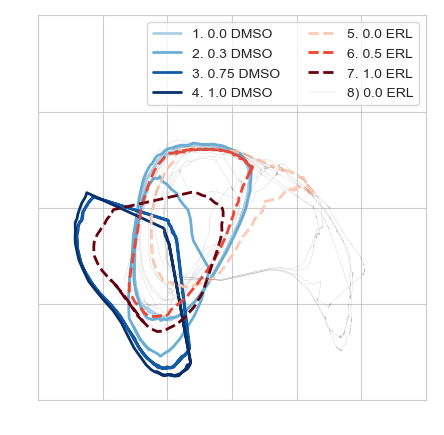

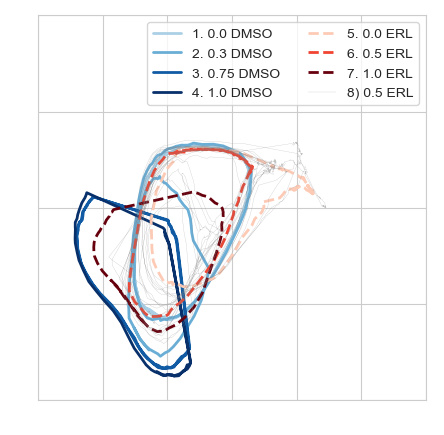

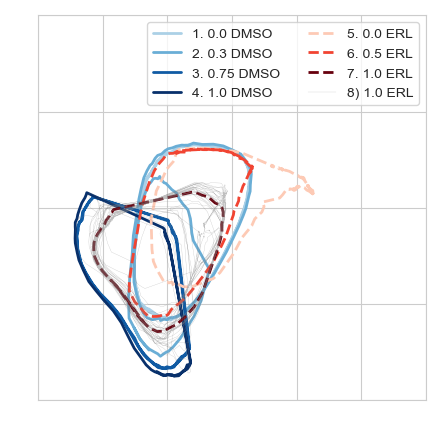

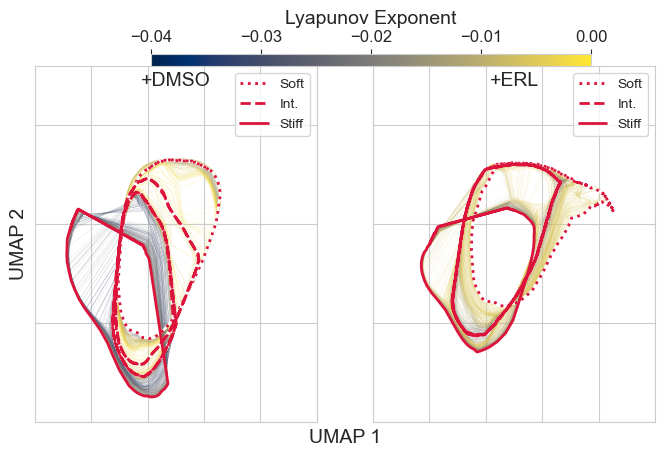

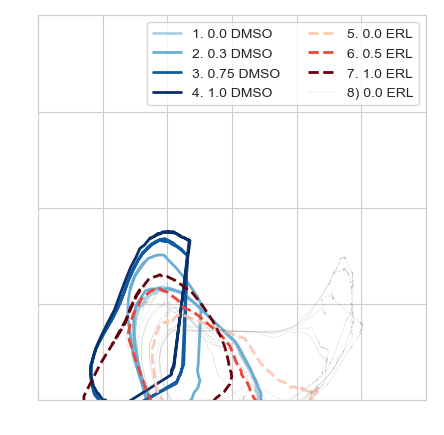

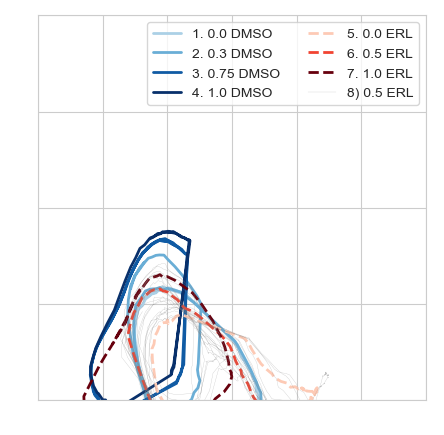

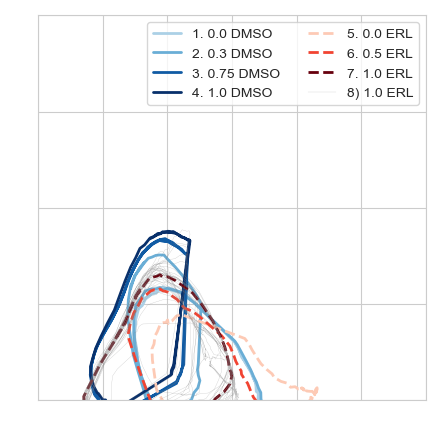

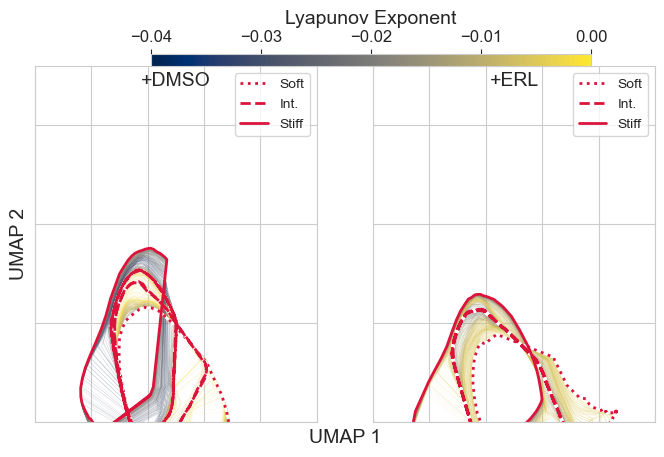

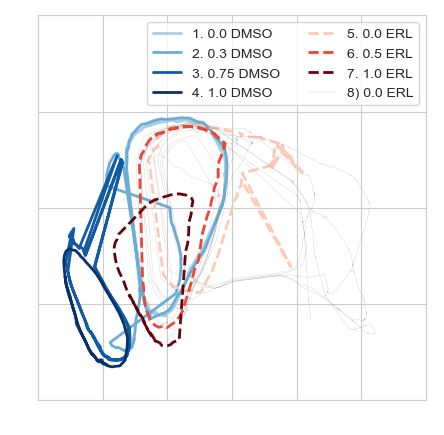

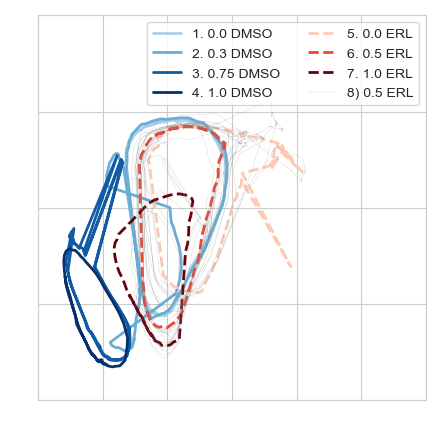

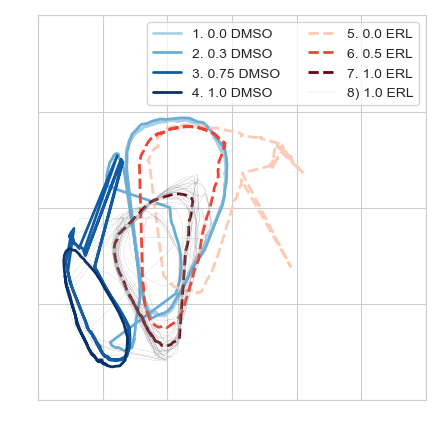

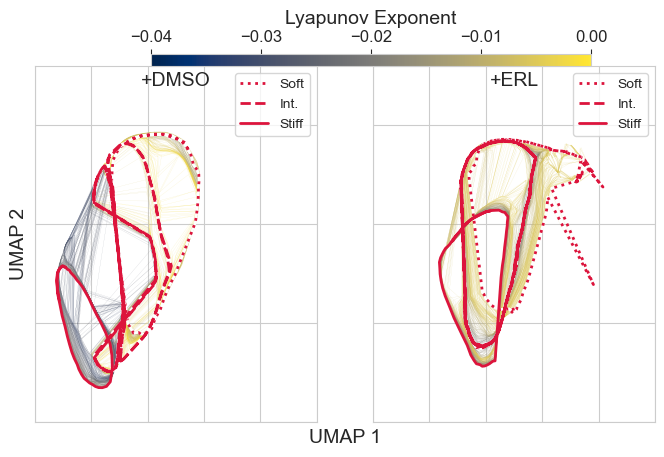

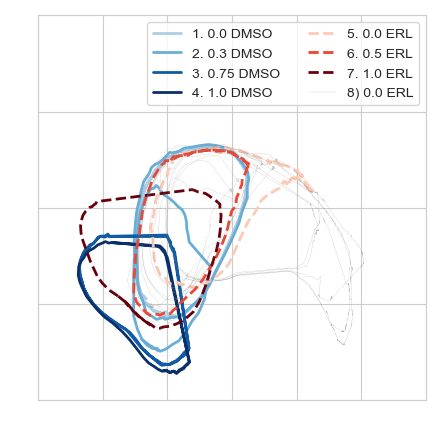

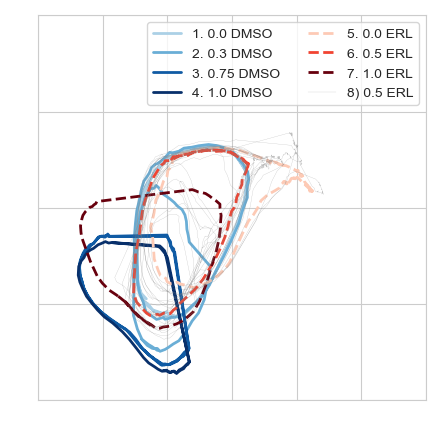

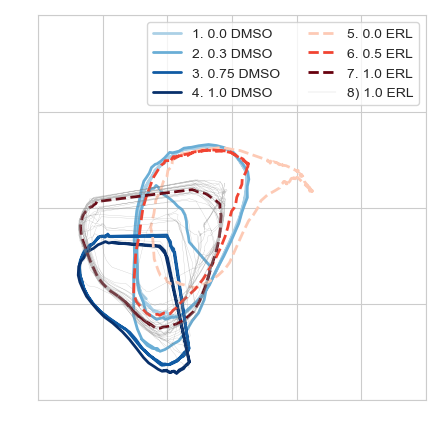

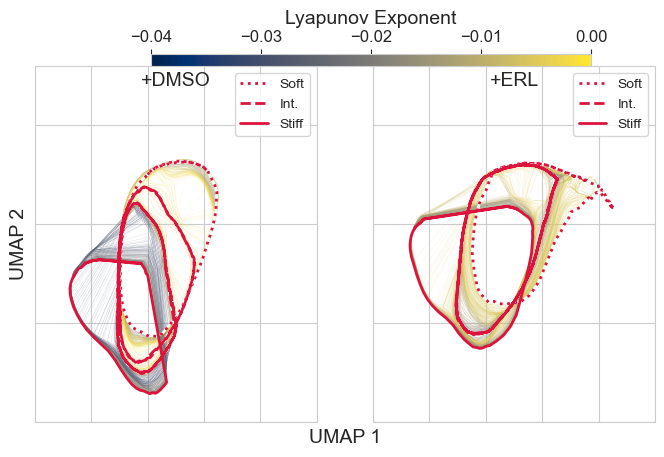

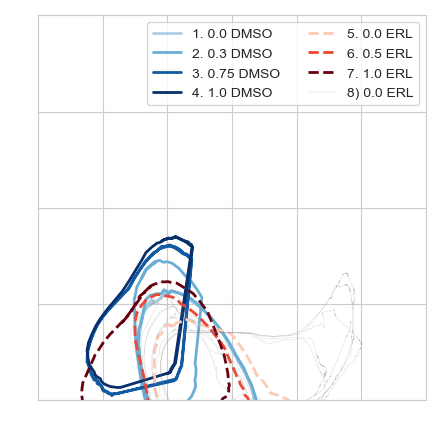

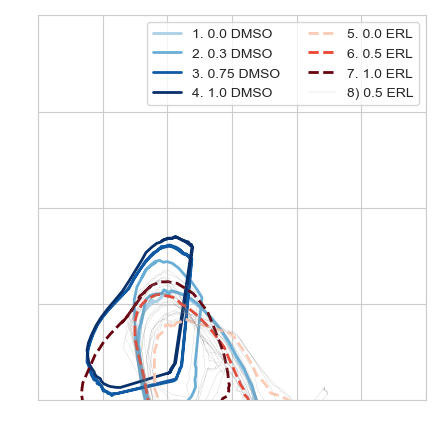

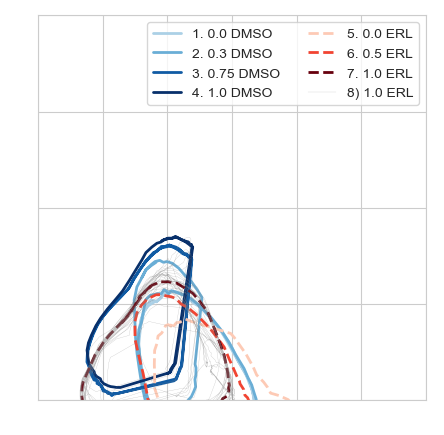

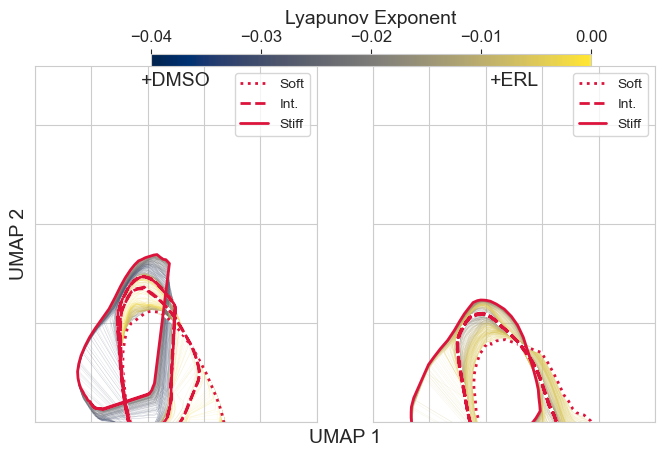

In [27]:
for wind in windows:
    window = wind
    
    [all_prot_umap, all_prot_ode_umap, all_time_umap, all_time_at_umap] = load_norm_data(stoch_filenames_umap, ode_filenames_umap, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)

    # Conditions identified in Lyapunov analysis
    [all_prot_lyap, all_prot_ode_lyap, all_time_lyap, all_time_at_lyap] = load_norm_data(stoch_filenames, ode_filenames, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)
    
    print(f"Window {wind} completed")
    
    for neighb in neighbors:
        neighbs = neighb
        
        reducer = umap.UMAP(
                    n_neighbors=neighbs,
                    min_dist=min_d,
                    n_components=2,
                    metric='euclidean',
                    random_state=RANDOM_STATE,
                    low_memory=True        
                    ).fit(all_prot_umap)
        
        print(f"Reducer {neighb} completed")
        
        win_len = int(window/dt)
        all_prot_tmp_ode_ab = np.empty((0,win_len*18))
        ab_len = 2000
        w_len = len(all_prot_ode_lyap)/len(ode_filenames)
        sp = 1
        for n in range(len(ode_filenames)):
            tmp = all_prot_ode_lyap[int(sp*w_len-ab_len):int(sp*w_len),:]
            all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
            sp += 1
        all_prot_tmp_stoch_ab = np.empty((0,win_len*18))
        w_len = len(all_prot_lyap)/len(stoch_filenames)
        sp = 1
        for n in range(len(stoch_filenames)):
            tmp = all_prot_lyap[int(sp*w_len-ab_len):int(sp*w_len),:]
            all_prot_tmp_stoch_ab = np.append(all_prot_tmp_stoch_ab, tmp, axis=0)
            sp += 1    
            
        all_embed_odes = reducer.transform(all_prot_tmp_ode_ab)
        all_embed_stoch = reducer.transform(all_prot_tmp_stoch_ab)
        
        conds = ['0.0 DMSO', '0.3 DMSO', '0.5 DMSO', '0.75 DMSO', '1.0 DMSO','0.0 ERL', '0.3 ERL', '0.5 ERL', '0.75 ERL', '1.0 ERL',]
        colors_blue = plt.cm.Blues(np.linspace(0,1,7))
        colors_red = plt.cm.Reds(np.linspace(0,1,6))
        cond_colors = [colors_blue[2], colors_blue[3], colors_blue[4], colors_blue[5], colors_blue[6], colors_red[1], colors_red[2], colors_red[3], colors_red[4], colors_red[5],]
        conds_idx = [0,1,2,3,4,5,6,7,8,9,]
        plot_ode_len = [120,100,0,100,60,150,0,80,0,60,]
        line_type = ['-', '-', '-', '-', '-', '--', '--', '--', '--', '--',]
        
        trk_len = 2000 # length of ODE trajectories
        if output_from == 3:
            num_conds = 6 # experimental conditions
        elif output_from == 1 or output_from == 4:
            num_conds = 10
        trk_len_stoch = int(len(all_embed_stoch)/num_conds) # lyapunov-determined stiffness conditions
        
        embed_array = all_embed_odes
        embed_array_stoch = all_embed_stoch
        
        # plot parameters
        size = (5,5)
        l = trk_len
        lw=2

        for cond_i,cond_x in enumerate([5,7,9,]):
            lw = 2
            fig = plt.figure(figsize=size)
        
        
            for i,x in enumerate([0,1,3,4,5,7,9,]):
                plt.plot(embed_array[x*l:x*l+plot_ode_len[x],0], 
                        embed_array[x*l:x*l+plot_ode_len[x],1], 
                        ls=line_type[x], lw=lw, alpha=1, color=cond_colors[x], label=f'{i+1}. {conds[x]}')
        
            plt.plot(embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch,0], 
                    embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch,1], 
                    lw=0.2, alpha=0.5, color='gray', label=f'8) {conds[cond_x]}')
        
        
            plt.xlim(-5,20)
            plt.ylim(0, 15)
            plt.xticks(np.arange(-10, 21, step=5))
            plt.yticks(np.arange(0, 21, step=5))
        
            plt.xticks(color='w')
            plt.yticks(color='w')
        
            handles, labels = plt.gca().get_legend_handles_labels()
            order = [0,1,2,3,4,5,6,7,]
            leg = plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)
        
            filepath = Path(SAVE_DIR,f'{conds[cond_x]}_stoch_wind_{wind}_neighb_{neighb}.png')
            plt.savefig(filepath, format='png', dpi=300)

        norm = plt.Normalize(-0.04, 0)
        cm = plt.cm.cividis
        sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)
        LYAP_DIR = Path(SAVE_DIR, 'Lyap_analysis')
        lyap_dmso = np.genfromtxt(Path(LYAP_DIR, 'lyap_dmso.csv'), delimiter=',')
        lyap_erl = np.genfromtxt(Path(LYAP_DIR, 'lyap_erl.csv'), delimiter=',')
        lyap_dmso = np.append(lyap_dmso, lyap_dmso[-1])
        lyap_erl = np.append(lyap_erl, lyap_erl[-1])
        size = (8, 4)
        xmin = -10
        xmax = 15
        ymin = 0
        ymax = 18
        wid = 1
        fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})
        
        params = {'axes.titley': 1,
                  'axes.titlepad': -14,
                  'axes.labelsize': 14,
                  'axes.titlesize': 14,
                  'xtick.labelsize': 12,
                  'ytick.labelsize': 12}
        plt.rcParams.update(params)
        
        ii = 0
        for f in filenames_odes_dmso_100:
            tmp_emb = calc_emb(f)
        
            axes[0].plot(tmp_emb[:, 0], tmp_emb[:, 1], color=cm(norm(lyap_dmso[ii])), lw=0.1, alpha=0.5)
            ii += 1
        
        ii = 0
        for f in filenames_odes_erl_100:
            tmp_emb = calc_emb(f)
        
            axes[1].plot(tmp_emb[:, 0], tmp_emb[:, 1], color=cm(norm(lyap_erl[ii])), lw=0.1, alpha=0.5)
            ii += 1
        
        lw = 2
        
        tmp_emb = calc_emb(filenames_odes_erl_100[0])
        tmp_l = int(len(tmp_emb) / 4)
        axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='white', lw=lw)
        axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='crimson', lw=lw, linestyle='dotted', label='Soft')
        tmp_emb = calc_emb(filenames_odes_erl_100[49])
        tmp_l = 600
        axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='white', lw=lw)
        axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='crimson', lw=lw, linestyle='dashed', label='Int.')
        tmp_emb = calc_emb(filenames_odes_erl_100[100])
        tmp_l = int(len(tmp_emb) / 4)
        axes[1].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='crimson', lw=lw, label='Stiff')
        plt.legend(loc=1)
        
        plt.rcParams['axes.titley'] = 1
        plt.rcParams['axes.titlepad'] = -14
        axes[1].set_xlim([xmin, xmax])
        axes[1].set_ylim([ymin, ymax])
        axes[1].title.set_text('+ERL')
        axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
        axes[1].axes.yaxis.set_ticklabels([])
        
        tmp_emb = calc_emb(filenames_odes_dmso_100[0])
        tmp_l = int(len(tmp_emb) / 4)
        axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='white', lw=lw)
        axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='crimson', lw=lw, linestyle='dotted', label='Soft')
        tmp_emb = calc_emb(filenames_odes_dmso_100[49])
        tmp_l = 430
        axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='white', lw=lw)
        axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='crimson', lw=lw, linestyle='dashed', label='Int.')
        tmp_emb = calc_emb(filenames_odes_dmso_100[100])
        tmp_l = int(len(tmp_emb) / 4)
        axes[0].plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1], color='crimson', lw=lw, label='Stiff')
        axes[0].legend(loc=1)
        
        axes[0].set_xlim([xmin, xmax])
        axes[0].set_ylim([ymin, ymax])
        axes[0].title.set_text('+DMSO')
        axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])
        
        axes[0].set_yticklabels([])
        axes[0].set_xticklabels([])
        axes[1].set_yticklabels([])
        axes[1].set_xticklabels([])
        
        fig.subplots_adjust(top=1)
        cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
        fig.colorbar(sm, cax=cbar_ax, ticks=[-0.04, -0.03, -0.02, -0.01, 0],
                     orientation='horizontal', location='top', label='Lyapunov Exponent')
        
        ax = fig.add_subplot(111, frameon=False)
        ax.set_xticks([])
        ax.set_yticks([])
        #plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
        ax.set_xlabel('UMAP 1', labelpad=5)
        ax.set_ylabel('UMAP 2', labelpad=5)
        
        fig4a_fn = Path(SAVE_DIR, f'lyap_wind_{wind}_neighb_{neighb}.png')
        
        plt.savefig(fig4a_fn, bbox_inches='tight')    
        
        
        

In [44]:
# [all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(stoch_filenames, ode_filenames, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)
# experimental conditions only
[all_prot_umap, all_prot_ode_umap, all_time_umap, all_time_at_umap] = load_norm_data(stoch_filenames_umap, ode_filenames_umap, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)

# Conditions identified in Lyapunov analysis
[all_prot_lyap, all_prot_ode_lyap, all_time_lyap, all_time_at_lyap] = load_norm_data(stoch_filenames, ode_filenames, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [45]:
reducer = umap.UMAP(
                    n_neighbors=neighbs,
                    min_dist=min_d,
                    n_components=2,
                    metric='euclidean',
                    random_state=RANDOM_STATE,
                    low_memory=True        
                    ).fit(all_prot_umap)

In [46]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_ode_lyap)/len(ode_filenames)
sp = 1
for n in range(len(ode_filenames)):
    tmp = all_prot_ode_lyap[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [47]:
win_len = int(window/dt)
all_prot_tmp_stoch_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_lyap)/len(stoch_filenames)
sp = 1
for n in range(len(stoch_filenames)):
    tmp = all_prot_lyap[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_stoch_ab = np.append(all_prot_tmp_stoch_ab, tmp, axis=0)
    sp += 1

In [48]:
all_embed_odes = reducer.transform(all_prot_tmp_ode_ab)

In [49]:
all_embed_stoch = reducer.transform(all_prot_tmp_stoch_ab)

In [50]:
conds = ['0.0 DMSO', '0.3 DMSO', '0.5 DMSO', '0.75 DMSO', '1.0 DMSO','0.0 ERL', '0.3 ERL', '0.5 ERL', '0.75 ERL', '1.0 ERL',]
colors_blue = plt.cm.Blues(np.linspace(0,1,7))
colors_red = plt.cm.Reds(np.linspace(0,1,6))
cond_colors = [colors_blue[2], colors_blue[3], colors_blue[4], colors_blue[5], colors_blue[6], colors_red[1], colors_red[2], colors_red[3], colors_red[4], colors_red[5],]
conds_idx = [0,1,2,3,4,5,6,7,8,9,]
plot_ode_len = [120,100,0,100,60,150,0,80,0,60,]
line_type = ['-', '-', '-', '-', '-', '--', '--', '--', '--', '--',]

# conds_idx_exp = [0,2,4,5,7,9,]
# exp_conds = [conds[i] for i in conds_idx_exp]
# exp_conds_names = ['soft DMSO', 'int DMSO', 'stiff DMSO', 'soft ERL', 'int ERL', 'stiff ERL',]

# lyap_conds_idx = [0,1,3,4,5,7,9,]
# lyap_conds = [conds[i] for i in lyap_conds_idx]

# colors_accent = plt.cm.jet(np.linspace(0,1,10))

In [51]:
trk_len = 2000 # length of ODE trajectories
 
if output_from == 3:
    num_conds = 6 # experimental conditions
elif output_from == 1 or output_from == 4:
    num_conds = 10
trk_len_stoch = int(len(all_embed_stoch)/num_conds) # lyapunov-determined stiffness conditions

embed_array = all_embed_odes
embed_array_stoch = all_embed_stoch

In [52]:
# plot parameters
size = (5,5)
l = trk_len
lw=2

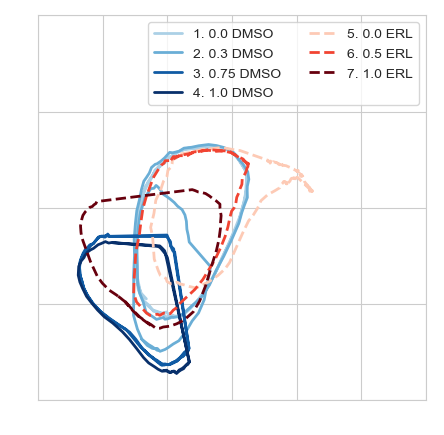

In [53]:
fig = plt.figure(figsize=size)

for i,x in enumerate([0,1,3,4,5,7,9,]):
    plt.plot(embed_array[x*l:x*l+plot_ode_len[x],0], 
             embed_array[x*l:x*l+plot_ode_len[x],1], 
             ls=line_type[x], lw=lw, alpha=1, color=cond_colors[x], label=f'{i+1}. {conds[x]}')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [0,1,2,3,4,5,6,]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)

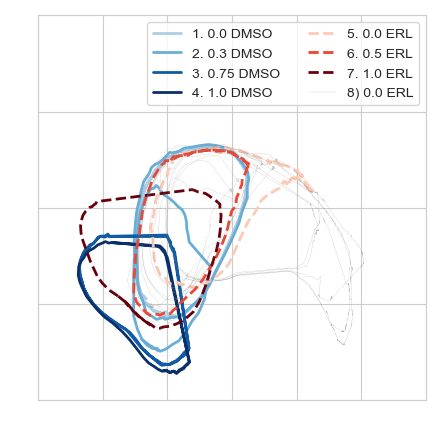

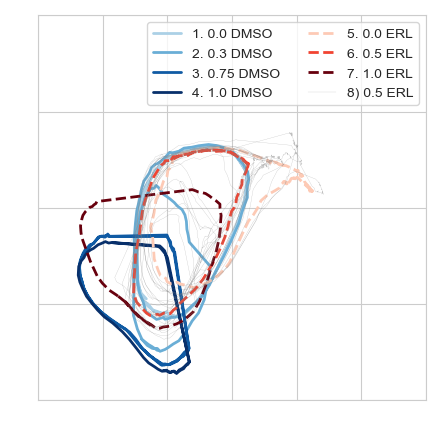

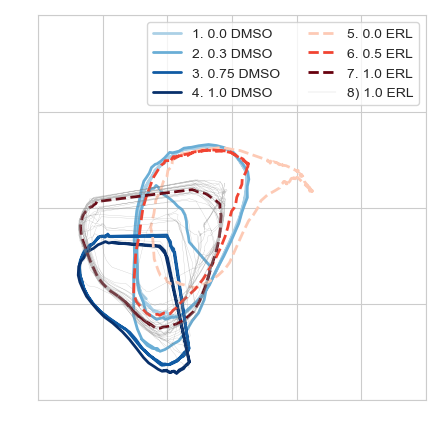

In [54]:
for cond_i,cond_x in enumerate([5,7,9,]):
    lw = 2
    fig = plt.figure(figsize=size)


    for i,x in enumerate([0,1,3,4,5,7,9,]):
        plt.plot(embed_array[x*l:x*l+plot_ode_len[x],0], 
                embed_array[x*l:x*l+plot_ode_len[x],1], 
                ls=line_type[x], lw=lw, alpha=1, color=cond_colors[x], label=f'{i+1}. {conds[x]}')

    plt.plot(embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch,0], 
            embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch,1], 
            lw=0.2, alpha=0.5, color='gray', label=f'8) {conds[cond_x]}')


    plt.xlim(-5,20)
    plt.ylim(0, 15)
    plt.xticks(np.arange(-10, 21, step=5))
    plt.yticks(np.arange(0, 21, step=5))

    plt.xticks(color='w')
    plt.yticks(color='w')

    handles, labels = plt.gca().get_legend_handles_labels()
    order = [0,1,2,3,4,5,6,7,]
    leg = plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)

    filepath = Path(SAVE_DIR,f'{conds[cond_x]}_stoch.png')
    plt.savefig(filepath, format='png', dpi=300)


In [109]:
norm = plt.Normalize(-0.04, 0)
cm = plt.cm.cividis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

In [113]:
LYAP_DIR = Path(SAVE_DIR,'Lyap_analysis')
lyap_dmso = np.genfromtxt(Path(LYAP_DIR,'lyap_dmso.csv'), delimiter=',')
lyap_erl = np.genfromtxt(Path(LYAP_DIR,'lyap_erl.csv'), delimiter=',')

In [114]:
lyap_dmso = np.append(lyap_dmso, lyap_dmso[-1])
lyap_erl = np.append(lyap_erl, lyap_erl[-1])

In [115]:
size = (8,4)
xmin = -10
xmax = 15
ymin = 0
ymax = 18
wid = 1

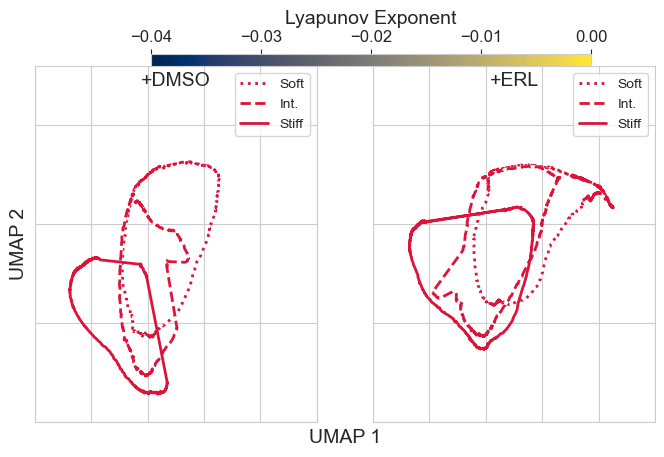

In [117]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_odes_dmso_100:
    tmp_emb = calc_emb(f)

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_dmso[ii])), lw=0.1, alpha=0.5)
    ii+=1

ii=0
for f in filenames_odes_erl_100:
    tmp_emb = calc_emb(f)

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_erl[ii])), lw=0.1, alpha=0.5)
    ii+=1
    

    
lw = 2

tmp_emb = calc_emb(filenames_odes_erl_100[0])
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = calc_emb(filenames_odes_erl_100[49])
tmp_l = 600
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = calc_emb(filenames_odes_erl_100[100])
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    


tmp_emb = calc_emb(filenames_odes_dmso_100[0])
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = calc_emb(filenames_odes_dmso_100[49])
tmp_l = 430
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = calc_emb(filenames_odes_dmso_100[100])
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)     


axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, ticks=[-0.04, -0.03, -0.02, -0.01, 0], 
             orientation='horizontal', location='top', label='Lyapunov Exponent')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVE_DIR, 'test.png')

plt.savefig(fig4a_fn, bbox_inches='tight')




In [55]:
# f = ode_filenames_umap[4]
f = filenames_odes_erl_100[50]
f

'C:\\Users\\olesk\\ECM_mod_output\\ODE_output\\ERL_range_499.csv'

In [59]:

prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
"Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
"cycB", "cycB-p21", "cdc20"]
prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])


range_ind = np.arange(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt))
#prot_tmp = prot_tmp/200
for ii in range(18):
    prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

prot_re_tmp = np.empty((len(range_ind),win_len*18))
time_re_tmp = np.empty((len(range_ind),win_len))
time_at_tmp = np.empty((len(range_ind),1))

ii=0
for n in range(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt)):
    tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
    #tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
    tmp=tmp.to_numpy()
    tmp=np.reshape(np.transpose(tmp),win_len*18)
    #tmp_at = time_tmp2['time'].iloc[n]

    prot_re_tmp[ii,:] = np.array([tmp])
    #time_re_tmp[ii,:] = np.array([tmp_t])
    #time_at_tmp[ii,:] = np.array([[tmp_at]])
    ii+=1

embedding_tmp = reducer.transform(prot_re_tmp)
# embedding_tmp = reducer.transform(prot_re_tmp[-2000:,:])


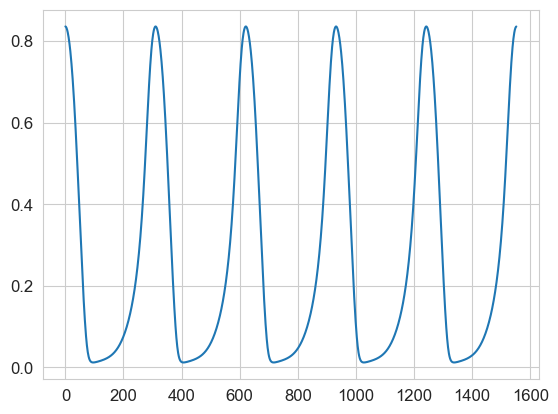

In [60]:
plt.plot(prot_tmp['cdc20'])


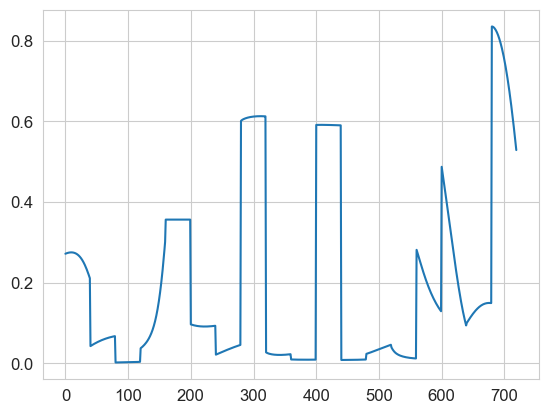

In [61]:
plt.plot(prot_re_tmp[0,:])
# plt.plot(prot_re_tmp[541,:])
# plt.plot(prot_re_tmp[550,:])

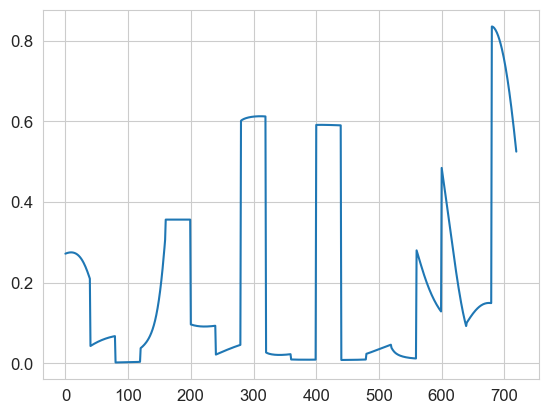

In [175]:
plt.plot(prot_re_tmp[540,:])

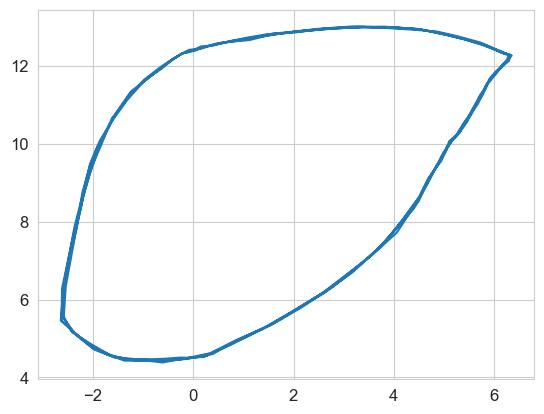

In [62]:
plt.plot(embedding_tmp[:,0], embedding_tmp[:,1])


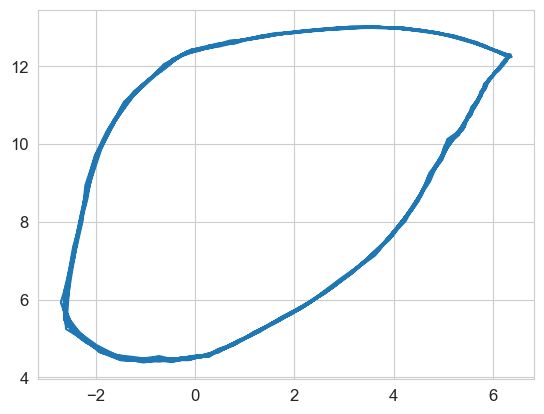

In [174]:
plt.plot(embedding_tmp[:,0], embedding_tmp[:,1])